# 3. Tabel siap pakai untuk Tableau

Membentuk tabel lokasi, udara per jam, udara harian, dan kesehatan harian. Rata-rata harian hanya dihitung bila minimal 18 dari 24 jam terisi. Tabel harian dilengkapi nilai maksimum 1 jam dan 8 jam, ISPU, dan penanda pelampauan baku mutu PP 22/2021; tabel kesehatan dilengkapi PM2.5 stasiun pasangannya beserta lag 1–7 hari.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd

RAW = "../data/raw/"
CLEAN = "../data/clean/"
MART = "../data/mart/"
OUT = "../hasil/"
POL = ["pm25", "pm10", "so2", "co", "o3", "no2"]
MET = ["temperature_c", "humidity_pct", "wind_speed_ms"]
DIKELUARKAN = {"JMB-02": "Dikeluarkan (sensor rusak)"}
TERBATAS = {"MER-01": "Data terbatas (hanya analisis per jam)"}
MIN_JAM = 18

In [3]:
KATEGORI = {
    "JKT-01": "Perkotaan", "YKY-01": "Perkotaan", "MLG-01": "Perkotaan", "BGL-01": "Perkotaan",
    "MDN-01": "Perkotaan", "PSW-01": "Perkotaan", "KTG-01": "Perkotaan",
    "JKT-03": "Tepi Jalan", "BGR-02": "Tepi Jalan",
    "JKT-02": "Industri", "BTM-01": "Industri", "MRS-01": "Industri", "SM2-01": "Industri",
    "BGR-01": "Latar Bersih", "IDP-01": "Latar Bersih", "KTB-01": "Latar Bersih", "PLU-01": "Latar Bersih",
    "SRG-01": "Latar Bersih", "MER-01": "Latar Bersih",
    "KTG-02": "Gambut", "PKU-01": "Gambut", "JMB-01": "Gambut", "STG-01": "Gambut",
    "PKN-01": "Gambut", "PLB-01": "Gambut", "BJB-01": "Gambut", "JMB-02": "Gambut",
}
PULAU = {
    "DKI Jakarta": "Jawa", "Jawa Barat": "Jawa", "D.I. Yogyakarta": "Jawa", "Jawa Timur": "Jawa",
    "Aceh": "Sumatera", "Sumatera Utara": "Sumatera", "Sumatera Barat": "Sumatera", "Riau": "Sumatera",
    "Kepulauan Riau": "Sumatera", "Jambi": "Sumatera", "Sumatera Selatan": "Sumatera",
    "Bengkulu": "Sumatera", "Lampung": "Sumatera",
    "Kalimantan Barat": "Kalimantan", "Kalimantan Tengah": "Kalimantan",
    "Kalimantan Selatan": "Kalimantan", "Kalimantan Timur": "Kalimantan",
    "Sulawesi Selatan": "Sulawesi", "Sulawesi Tengah": "Sulawesi",
    "Papua Barat Daya": "Papua", "Papua Selatan": "Papua",
}
BAKU_MUTU = {
    "pm25_24j": 55, "pm10_24j": 75, "so2_24j": 75, "no2_24j": 65,
    "so2_1j": 150, "no2_1j": 200, "co_1j": 10000, "o3_1j": 150,
    "co_8j": 4000, "o3_8j": 100,
}
ISPU_BP = {
    "pm25": [0, 15.5, 55.4, 150.4, 250.4, 500],
    "pm10": [0, 50, 150, 350, 420, 500],
}
ISPU_IDX = [0, 50, 100, 200, 300, 500]
KAT_ISPU = [(50, "Baik"), (100, "Sedang"), (200, "Tidak Sehat"), (300, "Sangat Tidak Sehat"), (np.inf, "Berbahaya")]
HARI = {"Monday": "Senin", "Tuesday": "Selasa", "Wednesday": "Rabu", "Thursday": "Kamis",
        "Friday": "Jumat", "Saturday": "Sabtu", "Sunday": "Minggu"}
NAMA_BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

In [4]:
def ispu(x, pol):
    bp = ISPU_BP[pol]
    return np.interp(np.clip(x, 0, bp[-1]), bp, ISPU_IDX)

In [5]:
def kategori_ispu(v):
    if pd.isna(v):
        return np.nan
    for batas, nama in KAT_ISPU:
        if v <= batas:
            return nama

In [6]:
def kolom_waktu(df, kol):
    t = pd.to_datetime(df[kol])
    df["tahun"] = t.dt.year
    df["bulan"] = t.dt.month
    df["nama_bulan"] = t.dt.month.map(lambda m: NAMA_BULAN[m - 1])
    df["hari"] = t.dt.day_name().map(HARI)
    df["akhir_pekan"] = t.dt.dayofweek >= 5
    df["musim"] = np.where(t.dt.month.between(5, 10), "Kemarau (Mei-Okt)", "Hujan (Nov-Apr)")
    return df

In [7]:
sites = pd.read_csv(RAW + "sites.csv")
sensors = pd.read_csv(RAW + "sensors.csv")
hospitals = pd.read_csv(RAW + "hospitals.csv")

dim = sites.copy()
dim["stasiun"] = dim["station_code"].str.replace("AQMS-", "", regex=False)
dim = dim.merge(sensors[["location_id", "sensor_id", "nama_sensor", "model_sensor", "tipe_pemasangan",
                         "status_operasional", "tanggal_instalasi"]], on="location_id", how="left")
dim["hospital_id"] = "RS-XXX-" + dim["sensor_id"].str[-2:]
dim = dim.merge(hospitals.rename(columns={"kota_kabupaten": "kota_kabupaten_rs", "kecamatan": "kecamatan_rs",
                                          "provinsi": "provinsi_rs"}), on="hospital_id", how="left")
dim["pulau"] = dim["provinsi"].map(PULAU)
dim["kategori_lokasi"] = dim["stasiun"].map(KATEGORI)
dim["wilayah_gambut"] = dim["site_type"].str.contains("Peatland") | dim["karakteristik_wilayah"].str.contains("Gambut")
dim["status_analisis"] = dim["stasiun"].map({**DIKELUARKAN, **TERBATAS}).fillna("Dianalisis penuh")
dim = dim.rename(columns={"latitude_dd": "latitude", "longitude_dd": "longitude", "nama_sensor": "nama_stasiun"})
dim = dim[["stasiun", "location_id", "sensor_id", "nama_stasiun", "provinsi", "kota_kabupaten", "kecamatan",
           "pulau", "region_group", "kategori_lokasi", "site_type", "wilayah_gambut", "karakteristik_wilayah",
           "latitude", "longitude", "baseline_pm25", "distance_to_road_m", "traffic_intensity_per_h",
           "model_sensor", "tipe_pemasangan", "status_operasional", "tanggal_instalasi", "status_analisis",
           "hospital_id", "nama_rumah_sakit", "kelas_faskes", "kapasitas_tempat_tidur"]]
assert dim["pulau"].notna().all() and dim["kategori_lokasi"].notna().all()
dim.to_csv(MART + "dim_lokasi.csv", index=False)

In [8]:
air = pd.read_csv(CLEAN + "air_hourly_clean.csv", parse_dates=["datetime"])
air = air.drop(columns="sensor_id")
air["tanggal"] = air["datetime"].dt.date
air["jam"] = air["datetime"].dt.hour
air = kolom_waktu(air, "datetime")
air["ispu_pm25_indikatif"] = ispu(air["pm25"], "pm25").round(0)
air.loc[air["pm25"].isna(), "ispu_pm25_indikatif"] = np.nan
air["kategori_pm25_indikatif"] = air["ispu_pm25_indikatif"].map(kategori_ispu)
air.to_csv(MART + "fakta_udara_per_jam.csv", index=False)

In [9]:
air = air.sort_values(["stasiun", "datetime"])
g = air.groupby("stasiun")
for p in ["co", "o3"]:
    air[p + "_8j"] = g[p].transform(lambda s: s.rolling(8, min_periods=6).mean())
air.loc[~air["jam"].between(13, 17), "o3_8j"] = np.nan

grp = air.groupby(["stasiun", "tanggal"])
harian = grp[POL + MET].mean()
jumlah = grp[POL].count()
for p in POL:
    harian.loc[jumlah[p] < MIN_JAM, p] = np.nan
harian["jam_terisi_pm25"] = jumlah["pm25"]
for p in ["so2", "no2", "co", "o3"]:
    harian[p + "_maks_1j"] = grp[p].max()
harian["co_maks_8j"] = grp["co_8j"].max()
harian["o3_maks_8j"] = grp["o3_8j"].max()
harian = harian.reset_index()
harian.loc[harian["stasiun"].isin(TERBATAS), POL + ["so2_maks_1j", "no2_maks_1j", "co_maks_1j", "o3_maks_1j",
                                                    "co_maks_8j", "o3_maks_8j"]] = np.nan
harian["hari_valid"] = harian["pm25"].notna()

In [10]:
harian["ispu_pm25"] = ispu(harian["pm25"], "pm25")
harian["ispu_pm10"] = ispu(harian["pm10"], "pm10")
harian.loc[harian["pm25"].isna(), "ispu_pm25"] = np.nan
harian.loc[harian["pm10"].isna(), "ispu_pm10"] = np.nan
harian["ispu"] = harian[["ispu_pm25", "ispu_pm10"]].max(axis=1).round(0)
harian["parameter_dominan"] = np.where(harian["ispu_pm25"] >= harian["ispu_pm10"].fillna(-1), "PM2.5", "PM10")
harian.loc[harian["ispu"].isna(), "parameter_dominan"] = np.nan
harian["kategori_ispu"] = harian["ispu"].map(kategori_ispu)
harian[["ispu_pm25", "ispu_pm10"]] = harian[["ispu_pm25", "ispu_pm10"]].round(0)

In [11]:
lewat = {
    "lewat_bm_pm25": harian["pm25"] > BAKU_MUTU["pm25_24j"],
    "lewat_bm_pm10": harian["pm10"] > BAKU_MUTU["pm10_24j"],
    "lewat_bm_so2": (harian["so2"] > BAKU_MUTU["so2_24j"]) | (harian["so2_maks_1j"] > BAKU_MUTU["so2_1j"]),
    "lewat_bm_no2": (harian["no2"] > BAKU_MUTU["no2_24j"]) | (harian["no2_maks_1j"] > BAKU_MUTU["no2_1j"]),
    "lewat_bm_co": (harian["co_maks_8j"] > BAKU_MUTU["co_8j"]) | (harian["co_maks_1j"] > BAKU_MUTU["co_1j"]),
    "lewat_bm_o3": (harian["o3_maks_8j"] > BAKU_MUTU["o3_8j"]) | (harian["o3_maks_1j"] > BAKU_MUTU["o3_1j"]),
}
for k, v in lewat.items():
    harian[k] = v.astype(int)
harian["jumlah_parameter_lewat_bm"] = harian[list(lewat)].sum(axis=1)
harian["lewat_who_pm25"] = (harian["pm25"] > 15).astype(int)
harian = kolom_waktu(harian, "tanggal")
num = harian.select_dtypes("float").columns
harian[num] = harian[num].round(2)
harian.to_csv(MART + "fakta_udara_harian.csv", index=False)

In [12]:
h = pd.read_csv(CLEAN + "health_daily_clean.csv", parse_dates=["date"])
h = h.rename(columns={"date": "tanggal"}).drop(columns=["time", "dow"])
peta = dim.set_index("hospital_id")["stasiun"]
h["stasiun"] = h["hospital_id"].map(peta)
pm = harian[["stasiun", "tanggal", "pm25", "pm10", "ispu", "kategori_ispu"]].copy()
pm["tanggal"] = pd.to_datetime(pm["tanggal"])
pm = pm.sort_values(["stasiun", "tanggal"])
for lag in range(1, 8):
    pm[f"pm25_lag{lag}"] = pm.groupby("stasiun")["pm25"].shift(lag)
pm["pm25_rata_lag0_2"] = pm[["pm25", "pm25_lag1", "pm25_lag2"]].mean(axis=1, skipna=False)
h = h.merge(pm, on=["stasiun", "tanggal"], how="left")
h = h.merge(dim[["hospital_id", "kapasitas_tempat_tidur", "status_analisis"]], on="hospital_id", how="left")
h["dipakai_analisis_dampak"] = h["status_analisis"].eq("Dianalisis penuh")
h = h.drop(columns="status_analisis")
h = kolom_waktu(h, "tanggal")
kol_kasus = ["resp_admissions_under5", "resp_admissions_over60", "asthma_emergency_cases", "copd_admissions", "resp", "cvd", "death", "kapasitas_tempat_tidur"]
h[kol_kasus] = h[kol_kasus].round().astype("Int64")
h.to_csv(MART + "fakta_kesehatan_harian.csv", index=False)

In [13]:
kamus = [
    ("dim_lokasi", "1 baris per stasiun (27, termasuk JMB-02 untuk peta)", "stasiun", "Master lokasi, karakteristik, sensor, dan RS pasangan"),
    ("fakta_udara_per_jam", "stasiun × jam (26 × 24.432)", "stasiun", "Polutan & cuaca per jam setelah cleaning, kategori PM2.5 indikatif"),
    ("fakta_udara_harian", "stasiun × hari (26 × 1.018)", "stasiun", "Rata-rata 24 jam, maks 1 jam & 8 jam, ISPU, flag melewati baku mutu"),
    ("fakta_kesehatan_harian", "RS × hari (27 × 1.018)", "stasiun, hospital_id", "Kasus kesehatan + PM2.5 hari yang sama dan lag 1–7 hari"),
]
aturan = [
    ("Rata-rata harian", f"Dihitung jika ≥ {MIN_JAM} dari 24 jam terisi (75%), per polutan"),
    ("MER-01", "Tidak punya nilai harian (hanya 10 hari memenuhi syarat); dipakai hanya untuk analisis per jam"),
    ("JMB-02", "Tidak ada di tabel fakta udara; tetap ada di dim_lokasi untuk peta dan bagian kualitas data"),
    ("ISPU harian", "Permen LHK 14/2020, interpolasi linear sepotong dari rata-rata 24 jam PM2.5 dan PM10; ISPU = nilai tertinggi; dibatasi 500"),
    ("ISPU per jam", "Hanya indikatif (ISPU resmi berbasis rata-rata 24 jam untuk partikulat)"),
    ("Baku mutu", "PP 22/2021 Lamp. VII: PM2.5 55, PM10 75, SO2 75 (24j)/150 (1j), NO2 65 (24j)/200 (1j), CO 4.000 (8j)/10.000 (1j), O3 100 (8j)/150 (1j) µg/m³"),
    ("O3 8 jam", "Rata-rata bergerak 8 jam yang berakhir pukul 13.00–18.00 (jendela 06.00–18.00 sesuai PP 22/2021)"),
    ("Pedoman WHO 2021", "PM2.5 24 jam 15 µg/m³ (lewat_who_pm25)"),
    ("Musim", "Kemarau Mei–Okt, Hujan Nov–Apr"),
    ("Lag PM2.5", "pm25_lagN = PM2.5 harian N hari sebelumnya di stasiun pasangan; pm25_rata_lag0_2 = rata-rata hari ini s.d. 2 hari sebelumnya"),
]
with pd.ExcelWriter(OUT + "03_kamus_data_mart.xlsx") as w:
    pd.DataFrame(kamus, columns=["tabel", "granularitas", "kunci_relasi_ke_dim_lokasi", "isi"]).to_excel(w, sheet_name="tabel", index=False)
    pd.DataFrame(aturan, columns=["aturan", "keterangan"]).to_excel(w, sheet_name="aturan_turunan", index=False)
    for nama, df in [("dim_lokasi", dim), ("fakta_udara_per_jam", air.drop(columns=["co_8j", "o3_8j"])),
                     ("fakta_udara_harian", harian), ("fakta_kesehatan_harian", h)]:
        pd.DataFrame({"kolom": df.columns, "tipe": df.dtypes.astype(str).values,
                      "contoh": [df[c].dropna().iloc[0] if df[c].notna().any() else "" for c in df.columns]}
                     ).to_excel(w, sheet_name=nama[:31], index=False)

In [14]:
print(dim[["stasiun", "pulau", "kategori_lokasi", "wilayah_gambut", "status_analisis", "hospital_id"]].to_string())
print("per jam", air.shape, "harian", harian.shape, "kesehatan", h.shape)
print(harian.groupby("stasiun")["hari_valid"].sum().to_string())
print(harian["kategori_ispu"].value_counts(dropna=False).to_string())
print(harian[[c for c in harian.columns if c.startswith("lewat")]].sum().to_string())
print(h["dipakai_analisis_dampak"].value_counts().to_string())

   stasiun       pulau kategori_lokasi  wilayah_gambut                         status_analisis hospital_id
0   JKT-01        Jawa       Perkotaan           False                        Dianalisis penuh   RS-XXX-01
1   JKT-02        Jawa        Industri           False                        Dianalisis penuh   RS-XXX-02
2   JKT-03        Jawa      Tepi Jalan           False                        Dianalisis penuh   RS-XXX-03
3   KTG-01  Kalimantan       Perkotaan            True                        Dianalisis penuh   RS-XXX-04
4   KTG-02  Kalimantan          Gambut            True                        Dianalisis penuh   RS-XXX-05
5   BGR-01        Jawa    Latar Bersih           False                        Dianalisis penuh   RS-XXX-06
6   BGR-02        Jawa      Tepi Jalan           False                        Dianalisis penuh   RS-XXX-07
7   YKY-01        Jawa       Perkotaan           False                        Dianalisis penuh   RS-XXX-08
8   IDP-01    Sumatera    Latar Bersi

## Ekspor ke format Hyper

Tabel yang sama juga disimpan sebagai satu file `.hyper` untuk Tableau.

In [15]:
import pandas as pd
from tableauhyperapi import (HyperProcess, Telemetry, Connection, CreateMode, TableDefinition,
                             SqlType, TableName, Inserter, NULLABLE)

MART = "../data/mart/"
TABEL = {
    "dim_lokasi": ([], []),
    "fakta_udara_per_jam": (["datetime"], ["tanggal"]),
    "fakta_udara_harian": ([], ["tanggal"]),
    "fakta_kesehatan_harian": ([], ["tanggal"]),
}

In [16]:
def tipe(s, nama, ts, tgl):
    if nama in ts:
        return SqlType.timestamp()
    if nama in tgl:
        return SqlType.date()
    if pd.api.types.is_bool_dtype(s):
        return SqlType.bool()
    if pd.api.types.is_integer_dtype(s):
        return SqlType.big_int()
    if pd.api.types.is_float_dtype(s):
        return SqlType.double()
    return SqlType.text()

In [17]:
with HyperProcess(Telemetry.DO_NOT_SEND_USAGE_DATA_TO_TABLEAU) as hp:
    with Connection(hp.endpoint, MART + "gelar_rasa_aqms.hyper", CreateMode.CREATE_AND_REPLACE) as con:
        con.catalog.create_schema_if_not_exists("Extract")
        for nama, (ts, tgl) in TABEL.items():
            df = pd.read_csv(MART + nama + ".csv", parse_dates=ts + tgl)
            for c in ts + tgl:
                df[c] = df[c].dt.date if c in tgl else df[c].dt.to_pydatetime()
            kolom = [TableDefinition.Column(c, tipe(df[c], c, ts, tgl), NULLABLE) for c in df.columns]
            t = TableDefinition(TableName("Extract", nama), kolom)
            con.catalog.create_table(t)
            baris = df.astype(object).where(df.notna(), None).values.tolist()
            with Inserter(con, t) as ins:
                ins.add_rows(baris)
                ins.execute()
            print(nama, len(df))

dim_lokasi 27


fakta_udara_per_jam 635232


fakta_udara_harian 26468


fakta_kesehatan_harian 27486


## Diagram relasi tabel

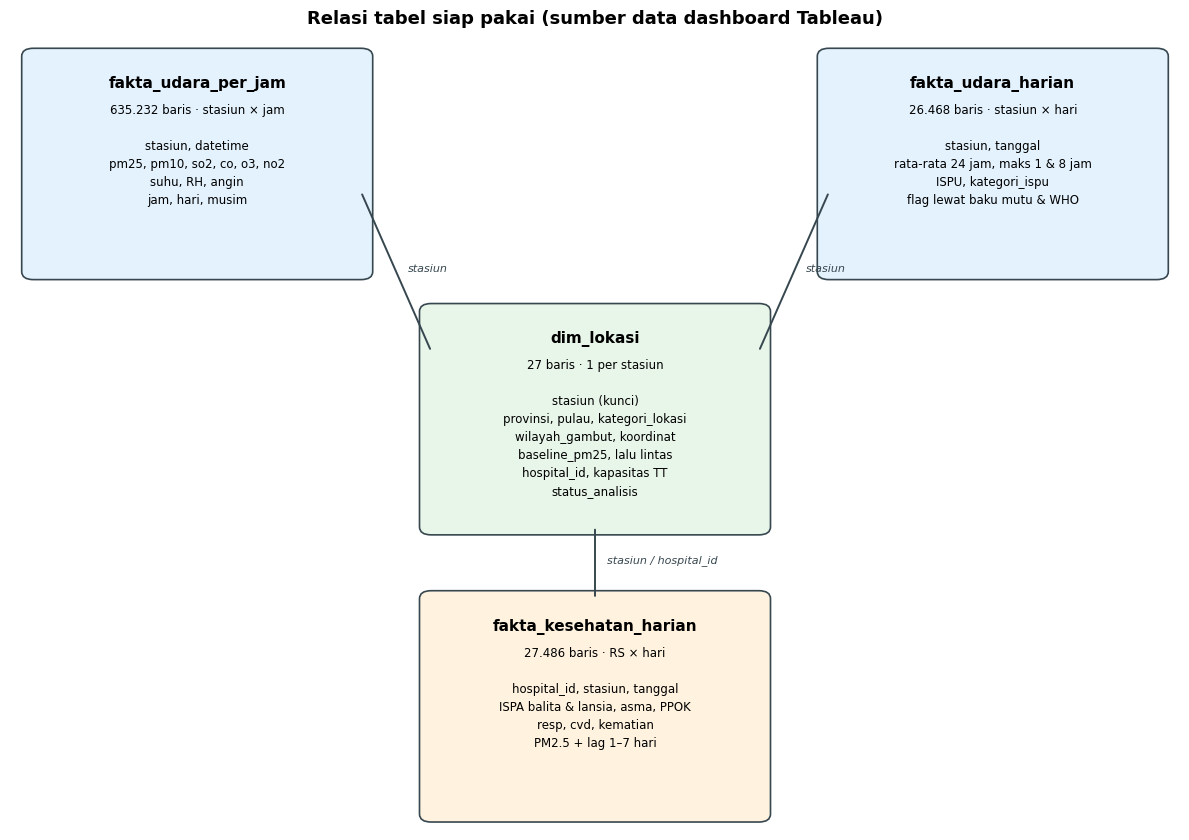

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

kotak = {
    "dim_lokasi": (0.36, 0.38, "dim_lokasi\n27 baris · 1 per stasiun\n\nstasiun (kunci)\nprovinsi, pulau, kategori_lokasi\nwilayah_gambut, koordinat\nbaseline_pm25, lalu lintas\nhospital_id, kapasitas TT\nstatus_analisis", "#e8f5e9"),
    "per_jam": (0.02, 0.70, "fakta_udara_per_jam\n635.232 baris · stasiun × jam\n\nstasiun, datetime\npm25, pm10, so2, co, o3, no2\nsuhu, RH, angin\njam, hari, musim", "#e3f2fd"),
    "harian": (0.70, 0.70, "fakta_udara_harian\n26.468 baris · stasiun × hari\n\nstasiun, tanggal\nrata-rata 24 jam, maks 1 & 8 jam\nISPU, kategori_ispu\nflag lewat baku mutu & WHO", "#e3f2fd"),
    "kesehatan": (0.36, 0.02, "fakta_kesehatan_harian\n27.486 baris · RS × hari\n\nhospital_id, stasiun, tanggal\nISPA balita & lansia, asma, PPOK\nresp, cvd, kematian\nPM2.5 + lag 1–7 hari", "#fff3e0"),
}
fig, ax = plt.subplots(figsize=(12, 8.5))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
w, h = 0.28, 0.27
for x, y, teks, warna in kotak.values():
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.01", fc=warna, ec="#37474f", lw=1.2))
    judul, isi = teks.split("\n", 1)
    ax.text(x + w / 2, y + h - 0.025, judul, ha="center", va="top", fontsize=11, weight="bold")
    ax.text(x + w / 2, y + h - 0.06, isi, ha="center", va="top", fontsize=8.5, linespacing=1.5)
pusat = (0.36 + w / 2, 0.38 + h / 2)
for a, b, lbl in [((0.30, 0.80), (0.36, 0.60), "stasiun"), ((0.70, 0.80), (0.64, 0.60), "stasiun"),
                  ((0.50, 0.29), (0.50, 0.38), "stasiun / hospital_id")]:
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-", color="#37474f", lw=1.4))
    ax.text((a[0] + b[0]) / 2 + 0.01, (a[1] + b[1]) / 2, lbl, fontsize=8, color="#37474f", style="italic")
ax.set_title("Relasi tabel siap pakai (sumber data dashboard Tableau)", fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig("../hasil/gambar/03_relasi_tabel.png", dpi=150)

## Status data sensor per stasiun

Tabel untuk grafik status sensor di halaman Metodologi. Dua belas status `qc_flag` dikelompokkan menjadi lima.

In [19]:
import glob
import re
import pandas as pd

KELOMPOK = {"VALID": "VALID", "SUSPECT": "SUSPECT",
            "CALIBRATING": "Alat tidak mengukur", "WARMUP": "Alat tidak mengukur", "MAINTENANCE": "Alat tidak mengukur",
            "MISSING": "MISSING",
            "PARSER_FAIL": "Galat sistem", "FATAL_ERR": "Galat sistem", "GARBAGE": "Galat sistem",
            "COMM_LOST": "Galat sistem", "CORRUPT": "Galat sistem", "SENSOR_DEAD": "Galat sistem"}
URUT = ["VALID", "SUSPECT", "Alat tidak mengukur", "MISSING", "Galat sistem"]

baris = []
for f in sorted(glob.glob("../data/raw/*_AQMS.csv")):
    kode = re.search(r"([A-Z0-9]+-\d+)_", f).group(1)
    q = pd.read_csv(f, usecols=["qc_flag"])["qc_flag"].value_counts()
    total = q.sum()
    agg = {}
    for flag, n in q.items():
        agg[KELOMPOK[flag]] = agg.get(KELOMPOK[flag], 0) + n
    for g in URUT:
        baris.append({"stasiun": kode, "kelompok_status": g, "urutan": URUT.index(g),
                      "jumlah_baris": int(agg.get(g, 0)), "persen": round(agg.get(g, 0) / total * 100, 2),
                      "total_baris": int(total)})
kualitas = pd.DataFrame(baris)
kualitas.to_csv("../data/mart/fakta_kualitas_data.csv", index=False)
tabel = kualitas.pivot(index="stasiun", columns="kelompok_status", values="persen")[URUT].sort_values("VALID")
tabel.round(1)

kelompok_status,VALID,SUSPECT,Alat tidak mengukur,MISSING,Galat sistem
stasiun,,,,,
JMB-02,0.5,13.7,0.0,0.0,85.8
MER-01,20.0,20.0,25.0,35.0,0.0
PLB-01,75.4,6.0,4.4,14.1,0.0
MDN-01,80.0,8.0,12.0,0.0,0.0
SM2-01,85.0,7.0,8.0,0.0,0.0
JKT-01,96.0,2.5,1.5,0.0,0.0
JKT-03,96.1,2.4,1.5,0.0,0.0
JKT-02,96.1,2.5,1.4,0.0,0.0
KTG-01,96.2,2.4,1.4,0.0,0.0


In [20]:
total = kualitas.drop_duplicates("stasiun")["total_baris"].sum()
valid = kualitas.loc[kualitas["kelompok_status"] == "VALID", "jumlah_baris"].sum()
print("Total baris mentah:", f"{total:,}".replace(",", "."))
print("Baris VALID:", f"{valid:,}".replace(",", "."), f"({valid / total * 100:.1f}%)")

Total baris mentah: 667.981
Baris VALID: 599.185 (89.7%)
